<a href="https://colab.research.google.com/github/dharshini-s1812/instacart-market-basket-analysis/blob/main/notebooks/02_Pandas_Analysis_and_Segmentation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Instacart Market Basket Analysis — Part 2: pandas Analysis & Customer Segmentation

**Pipeline:** `SQL (Notebook 1)` → `pandas (this notebook)` → `Tableau`

## Project goal
> *How can Instacart increase customer retention and basket size by understanding how customers order and reorder?*

## Role of this notebook
Notebook 1 produced descriptive summaries in SQL. Here pandas handles what SQL is awkward at:

| Step | What we do | Skills shown |
|------|-----------|--------------|
| Load | Read 32M rows on a laptop-class machine | dtype downcasting, Parquet caching |
| Validate | Data-quality & join-integrity checks, cross-check SQL vs pandas | `validate=` merges, assertions |
| Engineer | Favourite department, product diversity, preferred day/hour | vectorised lookups, `groupby`, `crosstab` |
| Explore | Does cart position predict reordering? | `groupby`, plotting |
| Basket analysis | Which aisles are bought together? (support & lift) | sparse matrices |
| Segment | Rule-based rhythm segments + K-means customer clusters | scaling, elbow/silhouette, PCA |
| Recommend | Turn segments into actions | business communication |
| Export | Compact tables for Tableau | |

**Input:** `outputs/sql_user_features.csv` (from Notebook 1) + the raw CSVs.

## Contents
1. Setup
2. Load data efficiently
3. Data-quality checks
4. Cross-check against the SQL layer
5. Feature engineering
6. Exploratory analysis
7. Aisle-level basket analysis
8. Customer segmentation
9. Segment profiles & recommendations
10. Export for Tableau

## 1. Setup

In [ ]:
import os
import gc
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

try:
    from google.colab import drive
    drive.mount('/content/drive')
except ImportError:
    print('Not running in Colab - using local paths.')

PROJECT_PATH   = '/content/drive/MyDrive/Instacart_Market_Basket_Analysis'
DATA_PATH      = os.path.join(PROJECT_PATH, 'data')
PROCESSED_PATH = os.path.join(DATA_PATH, 'processed')   # cached Parquet files
OUTPUT_PATH    = os.path.join(PROJECT_PATH, 'outputs')  # SQL outputs in, Tableau tables out

os.makedirs(PROCESSED_PATH, exist_ok=True)
os.makedirs(OUTPUT_PATH, exist_ok=True)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 50)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
sns.set_theme(style='whitegrid')

print(os.listdir(DATA_PATH))

Mounted at /content/drive
['aisles.csv', 'departments.csv', 'order_products__prior.csv', 'order_products__train.csv', 'orders.csv', 'products.csv', 'processed']


## 2. Load data efficiently

`order_products__prior.csv` has ~32M rows. With pandas' default dtypes (`int64`, `object`) it would use several GB. Choosing the smallest sufficient integer types cuts memory by well over half.

| Column | Default | Chosen | Why it is safe |
|--------|---------|--------|----------------|
| `order_id`, `product_id`, `user_id` | int64 | int32 | max ≈ 3.4M / 49K / 206K |
| `add_to_cart_order` | int64 | int16 | max ≈ 145 |
| `reordered`, `order_dow`, `order_hour_of_day` | int64 | int8 | tiny ranges |
| `days_since_prior_order` | float64 | float32 | whole numbers ≤ 30 (with NaN) |
| `eval_set` | object | category | 3 distinct values |

In [ ]:
ORDERS_DTYPES = {
    'order_id': 'int32', 'user_id': 'int32', 'eval_set': 'category',
    'order_number': 'int16', 'order_dow': 'int8', 'order_hour_of_day': 'int8',
    'days_since_prior_order': 'float32',
}
ORDER_PRODUCTS_DTYPES = {
    'order_id': 'int32', 'product_id': 'int32',
    'add_to_cart_order': 'int16', 'reordered': 'int8',
}


def read_csv(name, **kwargs):
    return pd.read_csv(os.path.join(DATA_PATH, f'{name}.csv'), **kwargs)


def mb(df):
    return df.memory_usage(deep=True).sum() / 1e6


# Small lookup tables
aisles      = read_csv('aisles',      dtype={'aisle_id': 'int16'})
departments = read_csv('departments', dtype={'department_id': 'int16'})
products    = read_csv('products',    dtype={'product_id': 'int32', 'aisle_id': 'int16', 'department_id': 'int16'})

# Orders: show the memory saving explicitly
orders_default = read_csv('orders')
mem_default = mb(orders_default)
del orders_default

orders = read_csv('orders', dtype=ORDERS_DTYPES)
print(f'orders memory: {mem_default:,.0f} MB (default dtypes) -> {mb(orders):,.0f} MB (optimised)'
      f'  [{1 - mb(orders) / mem_default:.0%} saved]')

orders memory: 349 MB (default dtypes) -> 58 MB (optimised)  [83% saved]


### Order-product history, cached as Parquet
The first run reads the CSV (slow) and saves a **Parquet** copy. Later runs load the Parquet file, which is typed, compressed and several times faster.

In [ ]:
PRIOR_PARQUET = os.path.join(PROCESSED_PATH, 'order_products_prior.parquet')

start = time.time()
if os.path.exists(PRIOR_PARQUET):
    order_products = pd.read_parquet(PRIOR_PARQUET)
    source = 'Parquet cache'
else:
    order_products = read_csv('order_products__prior', dtype=ORDER_PRODUCTS_DTYPES)
    order_products.to_parquet(PRIOR_PARQUET, index=False)
    source = 'CSV (Parquet cache created)'

print(f'Loaded {len(order_products):,} rows from {source} in {time.time() - start:.1f}s')
print(f'In-memory size: {mb(order_products):,.0f} MB')
order_products.dtypes

Loaded 32,434,489 rows from Parquet cache in 8.6s
In-memory size: 357 MB


,0
order_id,int32
product_id,int32
add_to_cart_order,int16
reordered,int8


In [ ]:
# Behaviour analysis uses prior orders only (train/test are Kaggle prediction targets)
prior_orders = orders[orders['eval_set'] == 'prior'].copy()
print(f'Prior orders: {len(prior_orders):,} | users: {prior_orders["user_id"].nunique():,}')
prior_orders.head()

Prior orders: 3,214,874 | users: 206,209


,order_id,user_id,eval_set,order_number,order_dow,order_hour_of_day,days_since_prior_order
0,2539329,1,prior,1,2,8,NaN
1,2398795,1,prior,2,3,7,15.000
2,473747,1,prior,3,3,12,21.000
3,2254736,1,prior,4,4,7,29.000
4,431534,1,prior,5,4,15,28.000


## 3. Data-quality checks

A short, explicit validation block shows that results can be trusted. Each check prints what was found *and* what was expected.

In [ ]:
dq = []

# 1. NULL days_since_prior_order should only occur on first orders
null_mask = orders['days_since_prior_order'].isna()
dq.append(('NULL days_since_prior_order on non-first orders', int((null_mask & (orders['order_number'] > 1)).sum()), 0))

# 2. Gap is top-coded at 30
dq.append(('Max days_since_prior_order', float(orders['days_since_prior_order'].max()), 30.0))

# 3. Duplicate keys
dq.append(('Duplicate order_id in orders', int(orders['order_id'].duplicated().sum()), 0))
dq.append(('Duplicate (order_id, product_id) rows', int(order_products.duplicated(['order_id', 'product_id']).sum()), 0))

# 4. Referential integrity
dq.append(('product_ids in orders missing from products',
           int((~np.isin(order_products['product_id'].unique(), products['product_id'])).sum()), 0))
dq.append(('order_ids in order_products missing from orders',
           int((~np.isin(order_products['order_id'].unique(), orders['order_id'])).sum()), 0))

pd.DataFrame(dq, columns=['check', 'found', 'expected']).assign(passed=lambda d: d['found'] == d['expected'])

,check,found,expected,passed
0,NULL days_since_prior_order on non-first orders,0.000,0.000,True
1,Max days_since_prior_order,30.000,30.000,True
2,Duplicate order_id in orders,0.000,0.000,True
3,"Duplicate (order_id, product_id) rows",0.000,0.000,True
4,product_ids in orders missing from products,0.000,0.000,True
5,order_ids in order_products missing from orders,0.000,0.000,True


### Safe merges
A silent join that duplicates or drops rows is one of the most common causes of wrong numbers. The helper below uses pandas' `validate=` argument and asserts that the row count is unchanged after a left join onto a lookup table.

In [ ]:
def safe_merge(left, right, on, how='left', validate='m:1'):
    """Merge and fail loudly if the row count changes unexpectedly."""
    n_before = len(left)
    out = left.merge(right, on=on, how=how, validate=validate)
    assert len(out) == n_before, f'Row count changed: {n_before:,} -> {len(out):,}'
    return out


# Demonstration on a 1M-row slice
demo = safe_merge(order_products.head(1_000_000), products[['product_id', 'aisle_id', 'department_id']], on='product_id')
demo = safe_merge(demo, departments, on='department_id')
print(f'Merge OK: {len(demo):,} rows preserved')
demo.head(3)

Merge OK: 1,000,000 rows preserved


,order_id,product_id,add_to_cart_order,reordered,aisle_id,department_id,department
0,2,33120,1,1,86,16,dairy eggs
1,2,28985,2,1,83,4,produce
2,2,9327,3,0,104,13,pantry


## 4. Cross-check against the SQL layer

Two independent implementations (SQL and pandas) of the same metrics should agree exactly. Matching totals prove both pipelines are correct.

### Fast lookups with NumPy arrays
Merging 32M rows several times is slow and memory-hungry. Because the IDs are dense integers, we use **array lookups** instead: `lookup[id]` is a vectorised "VLOOKUP" that takes a fraction of a second.

In [ ]:
def build_lookup(keys, values, dtype):
    """Dense array so that lookup[key] -> value."""
    arr = np.zeros(int(keys.max()) + 1, dtype=dtype)
    arr[keys.to_numpy()] = values.to_numpy()
    return arr


user_of_order    = build_lookup(orders['order_id'],     orders['user_id'],         'int32')
dept_of_product  = build_lookup(products['product_id'], products['department_id'], 'int16')
aisle_of_product = build_lookup(products['product_id'], products['aisle_id'],      'int16')

# Attach user and department to every order-product row (vectorised, no merge)
op_user = user_of_order[order_products['order_id'].to_numpy()]
op_dept = dept_of_product[order_products['product_id'].to_numpy()]
print(f'Lookups ready for {len(op_user):,} rows')

Lookups ready for 32,434,489 rows


In [ ]:
sql_users = pd.read_csv(os.path.join(OUTPUT_PATH, 'sql_user_features.csv'))
print(f'SQL user table: {len(sql_users):,} users')

# pandas recomputation
pd_orders_per_user = prior_orders.groupby('user_id').size().rename('n_orders_pd')
pd_items_per_user  = pd.Series(np.bincount(op_user, minlength=sql_users['user_id'].max() + 1)).rename('total_items_pd')

check = (sql_users.set_index('user_id')
         .join(pd_orders_per_user)
         .join(pd_items_per_user))

assert (check['n_orders'] == check['n_orders_pd']).all(),    'n_orders mismatch between SQL and pandas'
assert (check['total_items'] == check['total_items_pd']).all(), 'total_items mismatch between SQL and pandas'
print('SQL and pandas agree on n_orders and total_items for every user.')

SQL user table: 206,209 users
SQL and pandas agree on n_orders and total_items for every user.


## 5. Feature engineering

Starting from the SQL user table, we add behavioural features that describe *what* and *when* people buy, not just how much:

| Feature | Description |
|---------|-------------|
| `favorite_department` / `favorite_dept_share` | Department with the most items, and its share of the user's basket |
| `n_distinct_products` | Variety: how many different products the user has bought |
| `repeat_product_share` | Share of the user's products bought **more than once** (habit vs. exploration) |
| `preferred_dow` / `preferred_hour` | The user's most common order day and hour |

In [ ]:
users = sql_users.copy()

# --- Favourite department -------------------------------------------------------------
user_dept = (pd.DataFrame({'user_id': op_user, 'department_id': op_dept})
             .groupby(['user_id', 'department_id'], sort=False).size()
             .rename('n_items').reset_index())

fav = (user_dept.sort_values(['user_id', 'n_items'], ascending=[True, False])
       .drop_duplicates('user_id')
       .merge(departments, on='department_id', how='left', validate='m:1')
       .rename(columns={'department': 'favorite_department'}))

users = users.merge(fav[['user_id', 'favorite_department', 'n_items']], on='user_id', how='left', validate='1:1')
users['favorite_dept_share'] = users['n_items'] / users['total_items']
users = users.drop(columns='n_items')

del user_dept, fav
gc.collect()
users[['user_id', 'favorite_department', 'favorite_dept_share']].head()

,user_id,favorite_department,favorite_dept_share
0,1,snacks,0.373
1,2,dairy eggs,0.246
2,3,produce,0.432
3,4,beverages,0.167
4,5,produce,0.514


In [ ]:
# --- Product variety and repeat behaviour ---------------------------------------------
user_product = (pd.DataFrame({'user_id': op_user, 'product_id': order_products['product_id'].to_numpy()})
                .groupby(['user_id', 'product_id'], sort=False).size())

variety = pd.DataFrame({
    'n_distinct_products':  user_product.groupby(level=0).size(),
    'repeat_product_share': (user_product >= 2).groupby(level=0).mean(),
}).reset_index()

users = users.merge(variety, on='user_id', how='left', validate='1:1')

del user_product, variety
gc.collect()
users[['user_id', 'n_distinct_products', 'repeat_product_share']].head()

,user_id,n_distinct_products,repeat_product_share
0,1,18,0.556
1,2,102,0.363
2,3,33,0.576
3,4,17,0.059
4,5,23,0.348


In [ ]:
# --- Preferred day and hour -----------------------------------------------------------
preferred_dow  = pd.crosstab(prior_orders['user_id'], prior_orders['order_dow']).idxmax(axis=1).rename('preferred_dow')
preferred_hour = pd.crosstab(prior_orders['user_id'], prior_orders['order_hour_of_day']).idxmax(axis=1).rename('preferred_hour')

users = users.merge(preferred_dow.reset_index(),  on='user_id', how='left', validate='1:1')
users = users.merge(preferred_hour.reset_index(), on='user_id', how='left', validate='1:1')

assert len(users) == len(sql_users) and users['user_id'].is_unique
print(f'User table: {users.shape[0]:,} rows x {users.shape[1]} columns')
users.head()

User table: 206,209 rows x 13 columns


,user_id,n_orders,total_items,avg_basket_size,reorder_ratio,avg_days_between_orders,shopping_rhythm,favorite_department,favorite_dept_share,n_distinct_products,repeat_product_share,preferred_dow,preferred_hour
0,1,10,59,5.900,0.695,19.560,Every ~3 weeks,snacks,0.373,18,0.556,1,7
1,2,14,195,13.930,0.477,15.230,Bi-weekly,dairy eggs,0.246,102,0.363,1,10
2,3,12,88,7.330,0.625,12.090,Bi-weekly,produce,0.432,33,0.576,0,16
3,4,5,18,3.600,0.056,13.750,Bi-weekly,beverages,0.167,17,0.059,4,11
4,5,4,37,9.250,0.378,13.330,Bi-weekly,produce,0.514,23,0.348,3,18


## 6. Exploratory analysis

### 6.1 Does the position in the cart relate to reordering?
`add_to_cart_order` records the sequence in which items were added. Items added first tend to be habitual "must-haves". If reorder probability falls with position, it suggests customers start with their routine items and then add new ones, which has implications for where to place recommendations.

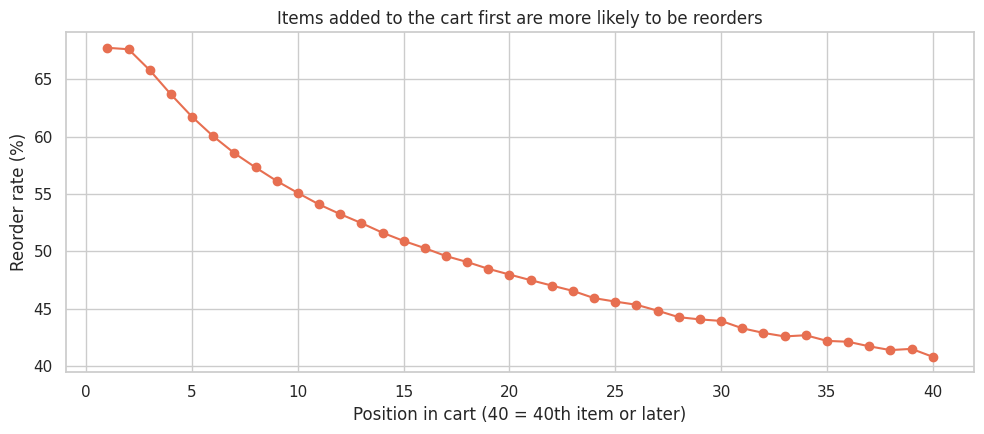

,add_to_cart_order,reorder_rate,n_items
0,1,0.678,3214874
1,2,0.676,3058126
2,3,0.658,2871133
3,4,0.637,2664106
4,5,0.617,2442025


In [ ]:
position = (order_products.groupby(order_products['add_to_cart_order'].clip(upper=40))['reordered']
            .agg(reorder_rate='mean', n_items='size')
            .reset_index())

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(position['add_to_cart_order'], position['reorder_rate'] * 100, marker='o', color='#e76f51')
ax.set_xlabel('Position in cart (40 = 40th item or later)')
ax.set_ylabel('Reorder rate (%)')
ax.set_title('Items added to the cart first are more likely to be reorders')
plt.tight_layout()
plt.show()
position.head()

**Shopping Behaviour Insight:**

Items added earlier to the cart exhibit significantly higher reorder rates than items added later. The reorder rate declines from 67.8% for the first item to approximately 47.9% for the twentieth item, representing a decrease of nearly 20 percentage points.

This suggests that customers tend to prioritize habitual purchases when building their carts, while later additions may involve more exploration or less frequently purchased products.

Business implication: E-commerce platforms could prioritize familiar products during the initial shopping experience and introduce personalized discovery recommendations as customers progress through their carts.

### 6.2 Distribution and relationships of user-level features

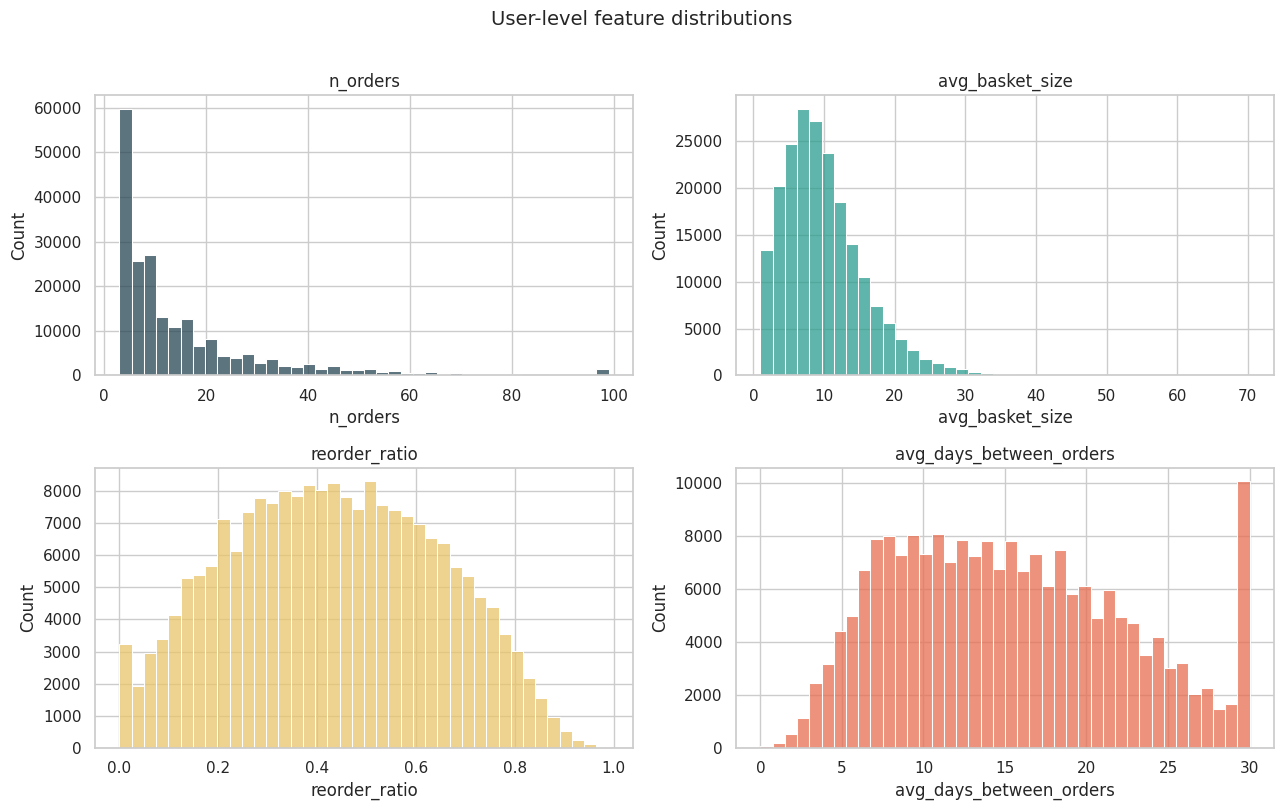

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for ax, col, color in zip(axes.ravel(),
                          ['n_orders', 'avg_basket_size', 'reorder_ratio', 'avg_days_between_orders'],
                          ['#264653', '#2a9d8f', '#e9c46a', '#e76f51']):
    sns.histplot(users[col], bins=40, ax=ax, color=color)
    ax.set_title(col)
plt.suptitle('User-level feature distributions', y=1.01, fontsize=14)
plt.tight_layout()
plt.show()

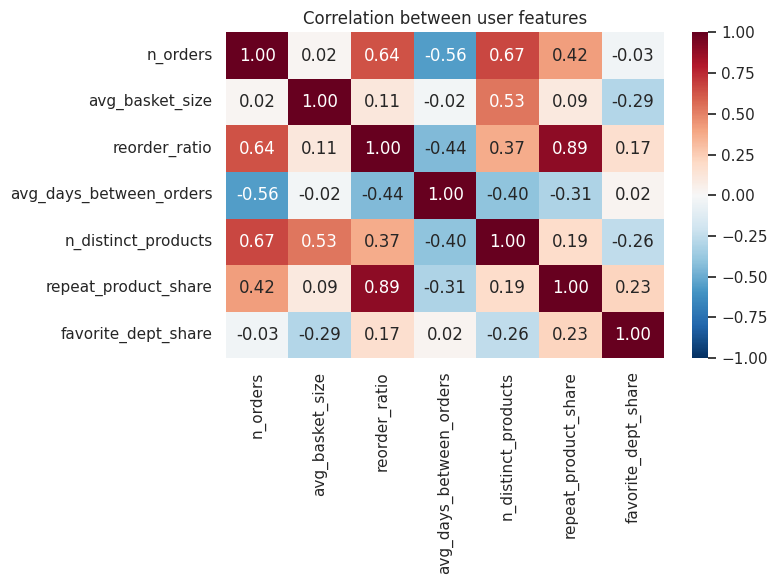

In [ ]:
feature_cols = ['n_orders', 'avg_basket_size', 'reorder_ratio', 'avg_days_between_orders',
                'n_distinct_products', 'repeat_product_share', 'favorite_dept_share']

plt.figure(figsize=(8, 6))
sns.heatmap(users[feature_cols].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, vmin=-1, vmax=1)
plt.title('Correlation between user features')
plt.tight_layout()
plt.show()

**Customer Behaviour Correlation Analysis**

The correlation analysis reveals a strong positive relationship (0.89) between reorder ratio and repeat product share, indicating substantial overlap in repeat-purchasing behaviour.

The number of orders is positively associated with the number of distinct products (0.67) and reorder ratio (0.64), suggesting that frequent shoppers generally exhibit broader purchasing behaviour and stronger repeat-purchase tendencies.

Additionally, the average number of days between orders has a negative correlation with order frequency (-0.56), highlighting differences in shopping frequency.

These relationships will inform feature selection before customer segmentation to minimize redundant information.

## 7. Aisle-level basket analysis

**Question:** which aisles tend to appear together in the *same order*? Pairs with high **lift** are natural candidates for cross-sell placement, bundles and "frequently bought together" prompts.

### Metrics
* **Support** of a pair = share of orders containing *both* aisles.
* **Lift** = `P(A and B) / (P(A) × P(B))`. Lift > 1 means the aisles co-occur *more than chance*; lift ≈ 1 means independence.

### Approach
Product-level pairs would be enormous, so we work at **aisle level** (134 aisles) on a **random sample of 100,000 orders**. Orders become rows of a sparse *order × aisle* matrix; multiplying the matrix by its transpose counts every co-occurrence at once.

In [ ]:
SAMPLE_ORDERS = 100_000
MIN_SUPPORT   = 0.01     # pair must appear in at least 1% of sampled orders

rng = np.random.default_rng(RANDOM_STATE)
prior_order_ids = prior_orders['order_id'].to_numpy()
sample_ids = rng.choice(prior_order_ids, size=min(SAMPLE_ORDERS, len(prior_order_ids)), replace=False)

mask = np.isin(order_products['order_id'].to_numpy(), sample_ids)
sample_orders = order_products['order_id'].to_numpy()[mask]
sample_aisles = aisle_of_product[order_products['product_id'].to_numpy()[mask]]

row_idx, order_labels = pd.factorize(sample_orders)
n_sample = len(order_labels)

basket = sparse.csr_matrix(
    (np.ones(len(row_idx), dtype=np.int32), (row_idx, sample_aisles.astype(np.int64))),
    shape=(n_sample, int(aisles['aisle_id'].max()) + 1),
)
basket.data[:] = 1                       # presence/absence: an aisle counts once per order

co_occurrence = (basket.T @ basket).toarray()
aisle_counts  = np.diag(co_occurrence).astype(float)
print(f'Sample: {n_sample:,} orders | matrix shape {basket.shape}')

Sample: 100,000 orders | matrix shape (100000, 135)


In [ ]:
i, j = np.triu_indices_from(co_occurrence, k=1)            # each unordered pair once
pairs = pd.DataFrame({
    'aisle_id_a': i, 'aisle_id_b': j,
    'orders_together': co_occurrence[i, j],
})
pairs = pairs[pairs['orders_together'] > 0].copy()

pairs['support'] = pairs['orders_together'] / n_sample
pairs['lift'] = (pairs['orders_together'] * n_sample /
                 (aisle_counts[pairs['aisle_id_a']] * aisle_counts[pairs['aisle_id_b']]))

names = aisles.set_index('aisle_id')['aisle']
pairs['aisle_a'] = pairs['aisle_id_a'].map(names)
pairs['aisle_b'] = pairs['aisle_id_b'].map(names)

# Exclude placeholder aisles and low-support pairs
placeholder = {'missing', 'other'}
pairs = pairs[(pairs['support'] >= MIN_SUPPORT)
              & ~pairs['aisle_a'].isin(placeholder) & ~pairs['aisle_b'].isin(placeholder)]

aisle_pairs = (pairs.sort_values('lift', ascending=False)
               [['aisle_a', 'aisle_b', 'orders_together', 'support', 'lift']]
               .reset_index(drop=True))
print(f'{len(aisle_pairs):,} aisle pairs pass the {MIN_SUPPORT:.0%} support threshold')
aisle_pairs.head(15)

818 aisle pairs pass the 1% support threshold


,aisle_a,aisle_b,orders_together,support,lift
0,pasta sauce,dry pasta,1966,0.020,4.446
1,canned meals beans,canned jarred vegetables,1813,0.018,3.616
2,frozen meals,frozen pizza,1051,0.011,3.335
3,canned jarred vegetables,spices seasonings,1079,0.011,2.870
4,soup broth bouillon,canned jarred vegetables,1655,0.017,2.735
5,frozen meals,frozen appetizers sides,1038,0.010,2.710
6,energy granola bars,fruit vegetable snacks,1053,0.011,2.665
7,canned jarred vegetables,dry pasta,1366,0.014,2.640
8,canned meals beans,tortillas flat bread,1006,0.010,2.621
9,fresh herbs,spices seasonings,1272,0.013,2.618


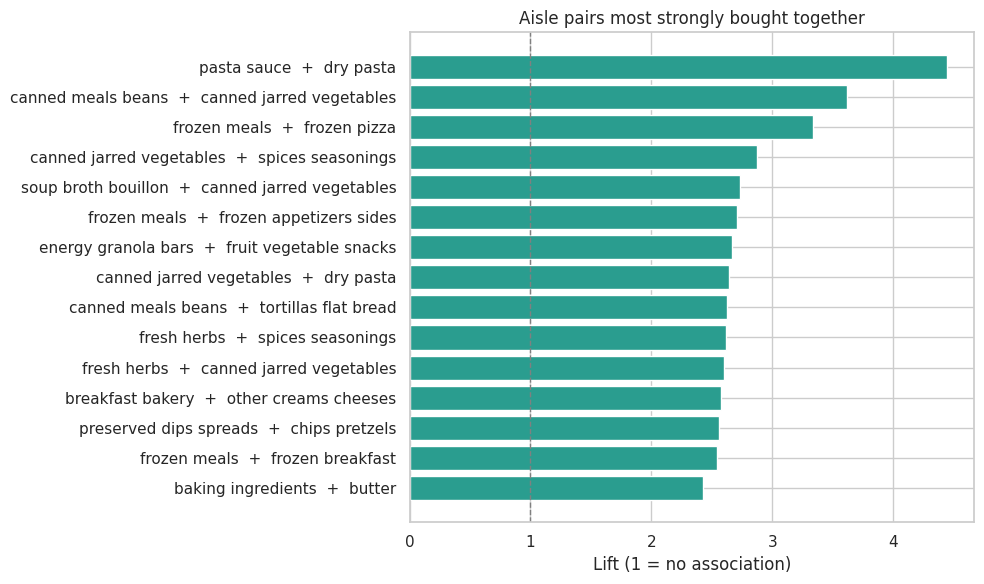

In [ ]:
top = aisle_pairs.head(15).iloc[::-1]
labels = top['aisle_a'] + '  +  ' + top['aisle_b']

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(labels, top['lift'], color='#2a9d8f')
ax.axvline(1, color='grey', linestyle='--', linewidth=1)
ax.set_xlabel('Lift (1 = no association)')
ax.set_title('Aisle pairs most strongly bought together')
plt.tight_layout()
plt.show()

**Market Basket Analysis – Business Insights**

The analysis identified several meaningful aisle associations, including dry pasta and pasta sauce, dips and chips, and canned beans and tortillas. These combinations reflect complementary purchasing behaviour and potential opportunities for cross-selling.

The strongest associations can support context-aware product recommendations and bundled offers. However, lift alone is insufficient to establish commercial value. Support and directional confidence should also be considered to ensure that recommendations are both statistically reliable and practically useful.

These findings demonstrate how transaction-level purchasing patterns can be translated into actionable merchandising strategies.

## 8. Customer segmentation

We build **two complementary segmentations**:

| Approach | Purpose |
|----------|---------|
| **Rule-based "shopping rhythm"** (from Notebook 1) | Simple, explainable, based on a single behaviour: how often a user shops |
| **K-means "behavioural clusters"** | Data-driven, combines frequency, basket size, loyalty and habit |

### 8.1 Prepare features for clustering
K-means uses distances, so features must be on comparable scales. Right-skewed variables (`n_orders`, `avg_basket_size`) are log-transformed first, then everything is standardised.

**Features used:** `n_orders`, `avg_basket_size`, `reorder_ratio`, `avg_days_between_orders`.

In [ ]:
CLUSTER_FEATURES = ['n_orders', 'avg_basket_size', 'reorder_ratio', 'avg_days_between_orders']

X = users[CLUSTER_FEATURES].copy()
X['n_orders']        = np.log1p(X['n_orders'])
X['avg_basket_size'] = np.log1p(X['avg_basket_size'])

assert X.notna().all().all(), 'Missing values in clustering features'

X_scaled = StandardScaler().fit_transform(X)
print('Scaled feature matrix:', X_scaled.shape)

Scaled feature matrix: (206209, 4)


### 8.2 Choosing the number of clusters
Two diagnostics:
* **Elbow (inertia):** look for where adding clusters stops reducing within-cluster variance much.
* **Silhouette score:** how well separated the clusters are (higher is better; computed on a 20,000-user sample for speed).

Treat the numbers as guidance, not as a rule. The final choice should also produce segments you can *describe and act on*.

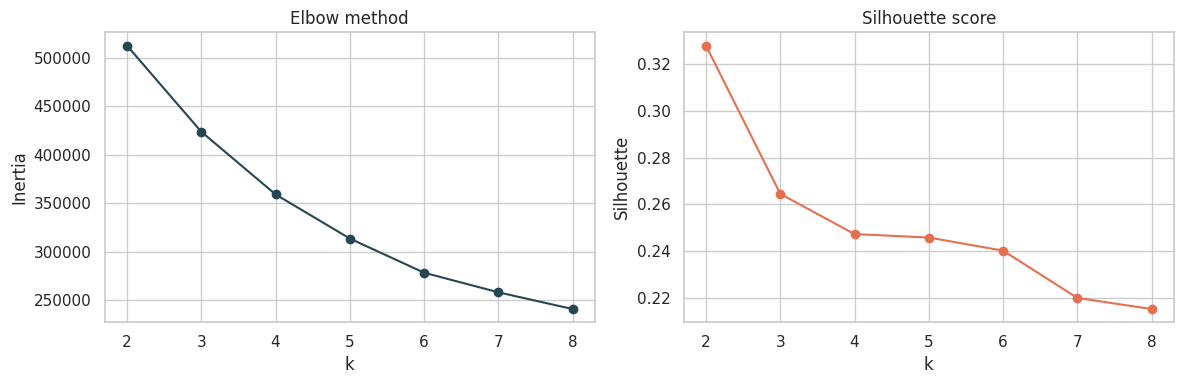

,k,inertia,silhouette
0,2,"512,402.896",0.328
1,3,"423,615.490",0.265
2,4,"358,965.141",0.247
3,5,"313,453.368",0.246
4,6,"278,211.899",0.240
5,7,"258,016.574",0.220
6,8,"240,742.673",0.215


In [ ]:
K_RANGE = range(2, 9)
inertias, silhouettes = [], []

for k in K_RANGE:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled, km.labels_, sample_size=20_000, random_state=RANDOM_STATE))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(K_RANGE), inertias, marker='o', color='#264653')
axes[0].set_title('Elbow method'); axes[0].set_xlabel('k'); axes[0].set_ylabel('Inertia')
axes[1].plot(list(K_RANGE), silhouettes, marker='o', color='#e76f51')
axes[1].set_title('Silhouette score'); axes[1].set_xlabel('k'); axes[1].set_ylabel('Silhouette')
plt.tight_layout()
plt.show()

pd.DataFrame({'k': list(K_RANGE), 'inertia': inertias, 'silhouette': silhouettes})

### 8.3 Fit the final model
`N_CLUSTERS = 4` is a sensible starting point (enough to be useful, few enough to act on). **Change it** if the diagnostics above point elsewhere, then re-run the cells below.

In [ ]:
N_CLUSTERS = 4

kmeans = KMeans(n_clusters=N_CLUSTERS, n_init=10, random_state=RANDOM_STATE).fit(X_scaled)
users['cluster'] = kmeans.labels_

users['cluster'].value_counts(normalize=True).sort_index().rename('share_of_users').to_frame()

,share_of_users
cluster,
0,0.306
1,0.259
2,0.235
3,0.200


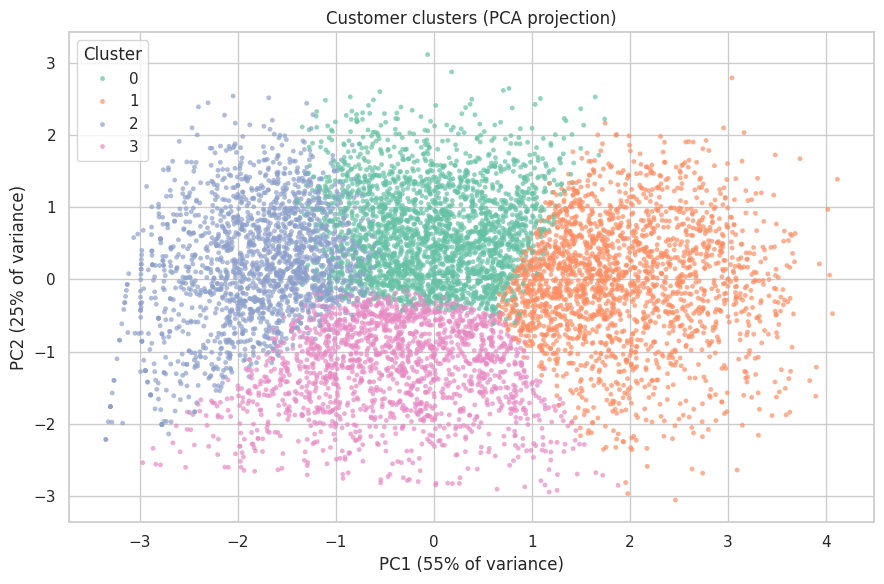

In [ ]:
# 2-D view of the clusters using PCA (on a 8,000-user sample for readability)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_scaled)
sample_idx = rng.choice(len(users), size=min(8_000, len(users)), replace=False)
coords = pca.transform(X_scaled[sample_idx])

plt.figure(figsize=(9, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=users['cluster'].to_numpy()[sample_idx],
                palette='Set2', s=12, alpha=0.7, linewidth=0)
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)')
plt.title('Customer clusters (PCA projection)')
plt.legend(title='Cluster')
plt.tight_layout()
plt.show()

## 9. Segment profiles & recommendations

### 9.1 Profile each cluster
The profile table shows the **average behaviour** of each cluster. The heatmap shows how far each cluster sits above (red) or below (blue) the overall average, which makes naming the clusters much easier.

In [ ]:
profile = (users.groupby('cluster')
           .agg(n_users=('user_id', 'count'),
                avg_orders=('n_orders', 'mean'),
                avg_basket_size=('avg_basket_size', 'mean'),
                reorder_ratio=('reorder_ratio', 'mean'),
                avg_days_between_orders=('avg_days_between_orders', 'mean'),
                n_distinct_products=('n_distinct_products', 'mean'),
                repeat_product_share=('repeat_product_share', 'mean'))
           .assign(pct_users=lambda d: d['n_users'] / d['n_users'].sum() * 100))
profile

,n_users,avg_orders,avg_basket_size,reorder_ratio,avg_days_between_orders,n_distinct_products,repeat_product_share,pct_users
cluster,,,,,,,,
0,63113,9.917,13.545,0.414,13.918,71.987,0.367,30.606
1,53467,36.862,10.359,0.667,8.753,114.629,0.511,25.929
2,48447,4.830,9.892,0.220,23.534,35.742,0.218,23.494
3,41182,9.326,3.986,0.406,15.778,21.956,0.374,19.971


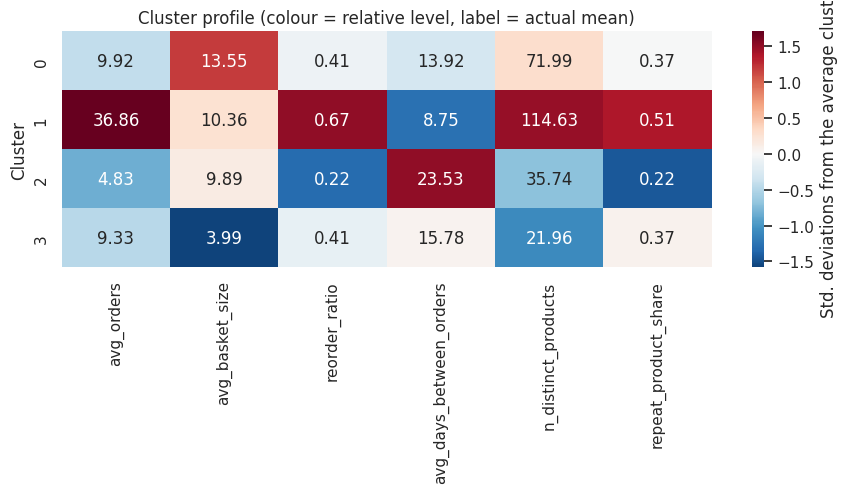

In [ ]:
metric_cols = ['avg_orders', 'avg_basket_size', 'reorder_ratio',
               'avg_days_between_orders', 'n_distinct_products', 'repeat_product_share']
relative = (profile[metric_cols] - profile[metric_cols].mean()) / profile[metric_cols].std(ddof=0)

plt.figure(figsize=(9, 3.5 + 0.4 * N_CLUSTERS))
sns.heatmap(relative, annot=profile[metric_cols].round(2), fmt='', cmap='RdBu_r', center=0,
            cbar_kws={'label': 'Std. deviations from the average cluster'})
plt.title('Cluster profile (colour = relative level, label = actual mean)')
plt.ylabel('Cluster')
plt.tight_layout()
plt.show()

### 9.2 Name the segments
Read the heatmap and give each cluster a short, meaningful name. **Edit the dictionary below** after reviewing *your* results; the cluster numbers can change between runs/versions, so the names must match the profiles.

Examples of the kind of names that tend to fit this dataset (do not copy them blindly):
* *"Loyal weekly regulars"*: many orders, short gaps, high reorder ratio
* *"Big-basket stock-up shoppers"*: large baskets, longer gaps
* *"Occasional / at-risk users"*: few orders, long gaps, low reorder ratio

In [ ]:
# EDIT after inspecting the profile table and heatmap above.
CLUSTER_NAMES = {
    # 0: 'Loyal weekly regulars',
    # 1: 'Big-basket stock-up shoppers',
    # 2: 'Occasional users',
    # 3: '...',
}

users['segment_name'] = users['cluster'].map(lambda c: CLUSTER_NAMES.get(c, f'Cluster {c}'))
users['segment_name'].value_counts()

,count
segment_name,
Cluster 0,63113
Cluster 1,53467
Cluster 2,48447
Cluster 3,41182


### 9.3 Compare with the rule-based rhythm segments
Do the data-driven clusters line up with the simple weekly / bi-weekly / monthly rules? Rows show, for each rhythm, what share of its users fall in each cluster.

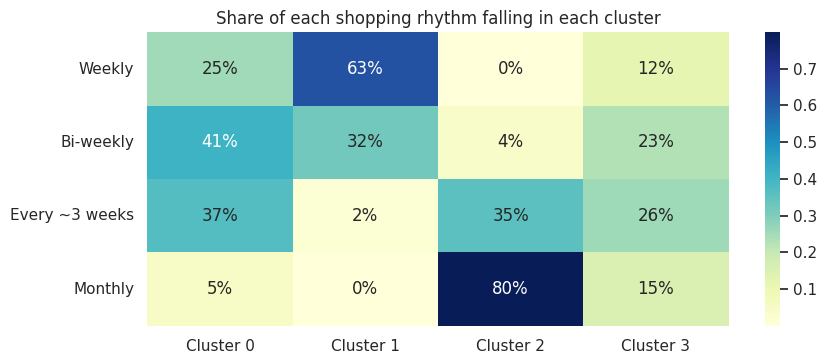

In [ ]:
rhythm_order = ['Weekly', 'Bi-weekly', 'Every ~3 weeks', 'Monthly']
cross = pd.crosstab(users['shopping_rhythm'], users['segment_name'], normalize='index').reindex(rhythm_order)

plt.figure(figsize=(9, 3.8))
sns.heatmap(cross, annot=True, fmt='.0%', cmap='YlGnBu')
plt.title('Share of each shopping rhythm falling in each cluster')
plt.ylabel('')
plt.xlabel('')
plt.tight_layout()
plt.show()

### 9.4 What does each segment buy? (favourite department mix)

In [ ]:
dept_mix = (users.groupby(['segment_name', 'favorite_department']).size()
            .rename('n_users').reset_index())
dept_mix['pct_of_segment'] = dept_mix['n_users'] / dept_mix.groupby('segment_name')['n_users'].transform('sum') * 100

top_depts = (dept_mix.sort_values(['segment_name', 'pct_of_segment'], ascending=[True, False])
             .groupby('segment_name').head(3))
top_depts

,segment_name,favorite_department,n_users,pct_of_segment
18,Cluster 0,produce,40744,64.557
6,Cluster 0,dairy eggs,9783,15.501
9,Cluster 0,frozen,3254,5.156
39,Cluster 1,produce,33829,63.271
27,Cluster 1,dairy eggs,8571,16.030
23,Cluster 1,beverages,4001,7.483
60,Cluster 2,produce,26500,54.699
48,Cluster 2,dairy eggs,7510,15.501
44,Cluster 2,beverages,3397,7.012
81,Cluster 3,produce,16639,40.404


### 9.5 Business recommendations *(template: complete this with your findings)*

Turn each segment into a concrete action. The best portfolio projects end here: *finding → implication → action → how to measure it*.

| Segment | Finding (from your profile) | Recommended action | Metric to track |
|---------|-----------------------------|--------------------|-----------------|
| *e.g. Loyal weekly regulars* | *High frequency and reorder ratio* | *"Buy it again" shortcuts, subscription / delivery-pass offers* | *Retention, orders per month* |
| *e.g. Stock-up shoppers* | *Large baskets, long gaps* | *Bundle deals; reminder before the usual restock date* | *Basket size, days between orders* |
| *e.g. Occasional users* | *Few orders, low reorder ratio* | *Re-engagement campaign; personalised discovery recommendations* | *Reactivation rate* |

Also connect the earlier analyses:
* **Timing (SQL, section 5):** schedule promotions and push notifications around peak day/hour windows.
* **Cart position (section 6.1):** habitual items come first, so test placing recommendations *after* them.
* **Basket analysis (section 7):** use high-lift aisle pairs for cross-sell placement.

## 10. Export for Tableau

Only small, aggregated tables go to Tableau. `tableau_user_segments.csv` has one row per user (~206K rows), which Tableau handles easily. Everything else is tiny.

| File | Suggested dashboard |
|------|--------------------|
| `tableau_user_segments.csv`, `tableau_segment_profile.csv`, `tableau_segment_department_mix.csv` | Customer segments |
| `tableau_aisle_pairs.csv` | Basket analysis / cross-sell |
| `tableau_reorder_by_position.csv` | Reorder behaviour |
| `sql_*.csv` (from Notebook 1) | Ordering patterns, product & department performance |

In [ ]:
export_cols = ['user_id', 'n_orders', 'total_items', 'avg_basket_size', 'reorder_ratio',
               'avg_days_between_orders', 'shopping_rhythm', 'favorite_department',
               'favorite_dept_share', 'n_distinct_products', 'repeat_product_share',
               'preferred_dow', 'preferred_hour', 'cluster', 'segment_name']

exports = {
    'tableau_user_segments.csv':          users[export_cols],
    'tableau_segment_profile.csv':        profile.reset_index().assign(segment_name=lambda d: d['cluster'].map(lambda c: CLUSTER_NAMES.get(c, f'Cluster {c}'))),
    'tableau_segment_department_mix.csv': dept_mix,
    'tableau_aisle_pairs.csv':            aisle_pairs,
    'tableau_reorder_by_position.csv':    position,
}

for filename, df in exports.items():
    df.to_csv(os.path.join(OUTPUT_PATH, filename), index=False)
    print(f'saved {filename:<38} {len(df):>9,} rows')

saved tableau_user_segments.csv                206,209 rows
saved tableau_segment_profile.csv                    4 rows
saved tableau_segment_department_mix.csv            83 rows
saved tableau_aisle_pairs.csv                      818 rows
saved tableau_reorder_by_position.csv               40 rows


## Summary

* Loaded 32M order-product rows efficiently (dtype downcasting + Parquet cache) and validated the data with explicit checks.
* Verified the SQL layer against an independent pandas computation.
* Engineered user-level behavioural features and analysed cart position vs. reordering.
* Found cross-sell opportunities with aisle-level support/lift.
* Built interpretable and data-driven customer segments and linked them to actions.

